<a href="https://colab.research.google.com/github/martalombardi/rhetorical_signatures/blob/refactor%2Fpipeline-rebuild/reddit_6.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# ArXiv Abstracts

In [1]:
# ============================================================
# 00 — COLAB / LOCAL NOTEBOOK INITIALIZATION
# ============================================================

from pathlib import Path
import importlib.util
import subprocess
import sys
import runpy

ROOT = Path("/content/rhetorical_signatures")

if not ROOT.is_dir():
    ROOT = Path.cwd().resolve()

INITIALIZER = ROOT / "code" / "initialize_experiment.py"

if not INITIALIZER.is_file():
    raise FileNotFoundError(f"Missing initializer: {INITIALIZER}")

print("Repository:", ROOT)
print("Python:", sys.executable)
print("Version:", sys.version.split()[0])

# ------------------------------------------------------------
# Install only missing RST dependencies in notebook Python
# ------------------------------------------------------------

missing_rst = (
    importlib.util.find_spec("isanlp") is None
    or importlib.util.find_spec("isanlp_rst") is None
)

if missing_rst:
    print("Installing missing RST dependencies...")

    subprocess.run(
        [
            "uv", "pip", "install",
            "--python", sys.executable,
            "git+https://github.com/iinemo/isanlp.git",
            "isanlp-rst",
        ],
        check=True,
    )

# ------------------------------------------------------------
# Verify RST imports
# ------------------------------------------------------------

from isanlp.annotation_rst import DiscourseUnit
from isanlp_rst.parser import Parser

print("RST dependencies OK")

# ------------------------------------------------------------
# Initialize experiment in current notebook kernel
# ------------------------------------------------------------

globals().update(runpy.run_path(str(INITIALIZER)))

print("Experiment initialized successfully.")

Repository: /content/rhetorical_signatures
Python: /usr/bin/python3
Version: 3.13.16
RST dependencies OK

Environment ready
-------------------------------------------------------
Python: 3.13.16
PyTorch: 2.14.1+cu130
CUDA available: True
spaCy: 3.8.18

Dataset selection
-------------------------------------------------------
Selection algorithm versions: {'matched': 3, 'unmatched': 1}
Mode: matched
k sentences: 6
m documents per source: None
Unmatched length bins: N/A
Seed: 42
Save selection: True
Generate selection plots: False

RST parsing
-------------------------------------------------------
Number of sentences: 6
Matched: True
Model: tchewik/isanlp_rst_v3
Model version: rstdt
Device: auto
Document limit: 200
Retry errors: False

XML forests
-------------------------------------------------------
Grouping variables: ['genre', 'source', 'n_sentences']
Rebuild: False
Validate: True
External metadata: None

TreeRePair compression
-----------------------------------------------------

In [2]:
''' runtime locale
from pathlib import Path
import runpy

ROOT = Path("/content/rhetorical_signatures")
_INITIALIZER = ROOT / "code" / "initialize_experiment.py"
if not _INITIALIZER.is_file():
    raise FileNotFoundError(f"Missing initializer: {_INITIALIZER}")

# run_path returns the variables defined by the initialization script;
# publish them to notebook globals for compatibility with cells 02 onward.
globals().update(runpy.run_path(str(_INITIALIZER)))
'''

' runtime locale\nfrom pathlib import Path\nimport runpy\n\nROOT = Path("/content/rhetorical_signatures")\n_INITIALIZER = ROOT / "code" / "initialize_experiment.py"\nif not _INITIALIZER.is_file():\n    raise FileNotFoundError(f"Missing initializer: {_INITIALIZER}")\n\n# run_path returns the variables defined by the initialization script;\n# publish them to notebook globals for compatibility with cells 02 onward.\nglobals().update(runpy.run_path(str(_INITIALIZER)))\n'

In [2]:
# ------------------------------------------------------------
# RAID dataset availability
# ------------------------------------------------------------

raid_downloader = load_project_module(
    "raid_downloader",
    PROCESSING_DIR / "01_download_raid.py",
)

raid_downloader.download_raid()

RAID dataset already available: /content/rhetorical_signatures/data/raw/raid/train.csv


PosixPath('/content/rhetorical_signatures/data/raw/raid/train.csv')

In [3]:
documents, sentences = unmatched_selector.load_or_analyze_sentence_lengths(
    domain=DOMAIN,
    prompting=PROMPTING,
    attack=ATTACK,
    decoding=DECODING,
    repetition_penalty=REPETITION_PENALTY,
    rebuild=SENTENCE_ANALYSIS_REBUILD,
    show_progress=SENTENCE_ANALYSIS_SHOW_PROGRESS,
)

print(f"Analyzed {len(documents):,} documents from {documents['source'].nunique()} sources")

Loaded existing sentence analysis: /content/rhetorical_signatures/results/sentences_report/domain-reddit__prompting-all__attack-null__decoding-greedy__rep-no
Analyzed 12,453 documents from 7 sources


# UNMATCHED

In [4]:
selected, statistics, metadata = unmatched_selector.select_unmatched_dataset(
    documents, sentences,
    k=K_SENTENCES,
    m=M_DOCUMENTS,
    domain=DOMAIN,
    prompting=PROMPTING,
    attack=ATTACK,
    decoding=DECODING,
    repetition_penalty=REPETITION_PENALTY,
    seed=SEED,
    n_bins=N_BINS,
    output_root=FILTERED_DIR,
    save=True,
    plot=False,
)

eligible, _ = unmatched_selector.prepare_unmatched_eligible(
    documents, sentences, K_SENTENCES
)

source_order = [s for s in MODEL_ORDER if s in selected["source"].unique()]

count_summary = pd.DataFrame({
    "eligible": eligible["source"].value_counts(),
    "selected": selected["source"].value_counts(),
}).reindex(source_order).astype(int)

assert count_summary["selected"].nunique() == 1
assert selected["n_sentences"].eq(K_SENTENCES).all()
assert selected["text"].notna().all()

print(f"Unmatched: k={K_SENTENCES}, {len(selected):,} documents")
display(count_summary, statistics)

Saved unmatched dataset: /content/rhetorical_signatures/data/filtered/unmatched/genre-reddit/prompting-all/attack-null/decoding-greedy/repetition_penalty-no/k-6/balanced-all__bins-10__seed-42
Eligible: 11,048 | balanced: 1,390 per source | selected: 9,730
Unmatched: k=6, 9,730 documents


,eligible,selected
source,,
Human,1615,1390
ChatGPT,1527,1390
GPT-4,1762,1390
Mistral 7B,1714,1390
Mistral 7B (Chat),1390,1390
Cohere,1642,1390
Cohere (Chat),1398,1390


,source,n_documents,n_sentences_total,sentences_per_document_mean,sentences_per_document_std,sentences_per_document_median,sentences_per_document_q05,sentences_per_document_q25,sentences_per_document_q75,sentences_per_document_q95,...,words_per_document_q25,words_per_document_q75,words_per_document_q95,words_per_sentence_mean,words_per_sentence_std,words_per_sentence_median,words_per_sentence_q05,words_per_sentence_q25,words_per_sentence_q75,words_per_sentence_q95
0,ChatGPT,1390,8340,6.0,0.0,6.0,6.0,6.0,6.0,6.0,...,83.0,109.00,130.00,16.029376,6.190754,16.0,6.0,12.0,20.0,26.0
1,Cohere,1390,8340,6.0,0.0,6.0,6.0,6.0,6.0,6.0,...,77.0,121.75,171.00,17.161751,11.041880,15.0,4.0,9.0,22.0,37.0
2,Cohere (Chat),1390,8340,6.0,0.0,6.0,6.0,6.0,6.0,6.0,...,79.0,121.00,163.00,17.229017,9.760795,16.0,4.0,10.0,22.0,35.0
3,GPT-4,1390,8340,6.0,0.0,6.0,6.0,6.0,6.0,6.0,...,83.0,109.00,128.00,16.066427,6.390191,16.0,6.0,12.0,20.0,27.0
4,Human,1390,8340,6.0,0.0,6.0,6.0,6.0,6.0,6.0,...,85.0,131.00,169.55,18.284652,11.550565,16.0,5.0,10.0,24.0,39.0
5,Mistral 7B,1390,8340,6.0,0.0,6.0,6.0,6.0,6.0,6.0,...,56.0,85.00,115.00,12.298321,10.405162,12.0,2.0,7.0,16.0,23.0
6,Mistral 7B (Chat),1390,8340,6.0,0.0,6.0,6.0,6.0,6.0,6.0,...,83.0,114.00,140.00,16.545923,6.650901,16.0,6.0,12.0,21.0,28.0


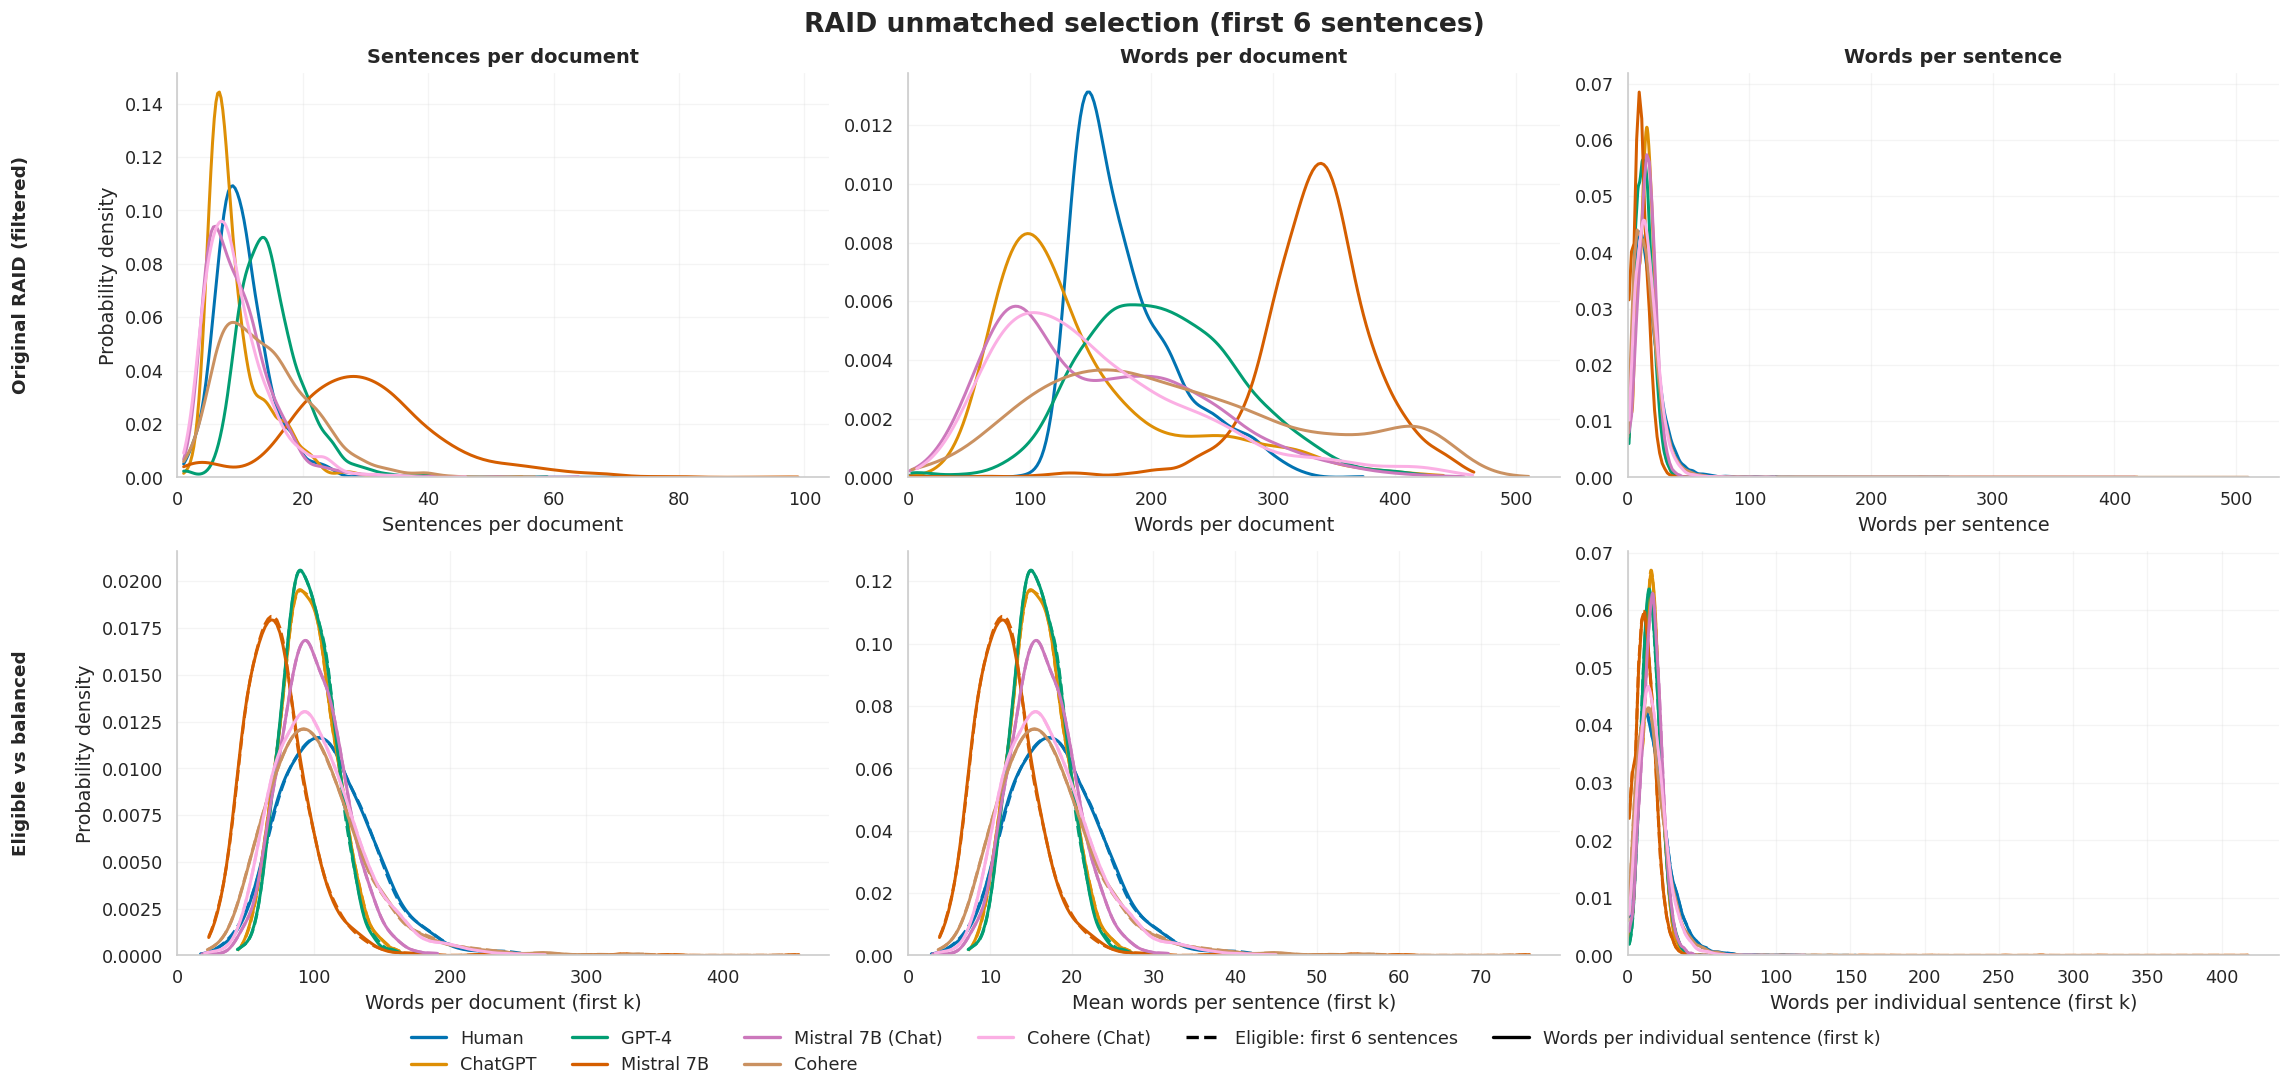

In [5]:
unmatched_selector.plot_unmatched_distributions(
    documents, sentences, selected, k=K_SENTENCES
)

### Parsing

In [6]:
# ============================================================
# 02 — Load or parse RST trees
# ============================================================

output, trees = rst.load_or_parse_dataset(
    domain=DOMAIN,
    prompting=PROMPTING,
    attack=ATTACK,
    decoding=DECODING,
    repetition_penalty=REPETITION_PENALTY,
    min_sentences=MIN_SENTENCES,
    max_sentences=MAX_SENTENCES,
    n_sentences=N_SENTENCES,
    matched=RST_MATCHED,
    sampling=SAMPLING,
    seed=SEED,
    n_bins=N_BINS,
    include_human=INCLUDE_HUMAN,
    model=RST_MODEL,
    model_version=RST_MODEL_VERSION,
    device=RST_DEVICE,
    retry_errors=RST_RETRY_ERRORS,
    limit=RST_LIMIT,
    rebuild=RST_REBUILD,
    output_root=RST_DATA_DIR,
)

print(f"RST trees loaded: {len(trees)}")
print(f"Output: {output}")

NameError: name 'MIN_SENTENCES' is not defined

### Build forests

In [ ]:
# ============================================================
# 03 — Load or build grouped XML forests
# ============================================================

(
    forests_dir,
    forest_paths,
    forest_index,
    manifest,
) = forest_builder.load_or_build_forests(
    trees_file=Path(output) / "trees.jsonl",
    metadata_file=FOREST_METADATA_FILE,
    group_by=FOREST_GROUP_BY,
    rebuild=FOREST_REBUILD,
    validate=FOREST_VALIDATE,
)


XML FORESTS READY
Forests: 7
RST trees: 2947
Directory: /content/rhetorical_signatures/data/rst/unmatched/domain-abstracts__prompting-all__attack-null__decoding-greedy__rep-no/range-6-10__best-6__matched-0__proportional__seed-42__bins-10__human-1/forests


# TreeRePair

In [ ]:

# ============================================================
# 04 — TreeRePair grammar compression
# ============================================================

compression_dir, compression_results, compression_manifest = (
    tree_compressor.run_treerepair(
        forests_dir=forests_dir,
        binary=TREEREPAIR_BINARY,
        genre=COMPRESSION_GENRE,
        n_sentences=COMPRESSION_N_SENTENCES,
        sources=COMPRESSION_SOURCES,
        rebuild=COMPRESSION_REBUILD,
        textual=COMPRESSION_TEXTUAL,
        optimize=COMPRESSION_OPTIMIZE,
        max_rank=COMPRESSION_MAX_RANK,
        timeout=COMPRESSION_TIMEOUT,
        continue_on_error=COMPRESSION_CONTINUE_ON_ERROR,
    )
)

compression_summary = pd.DataFrame(compression_results)

display(compression_summary)


[1/7] ChatGPT
  COMPLETED_UNVALIDATED (returncode=0)
[2/7] Cohere
  COMPLETED_UNVALIDATED (returncode=0)
[3/7] Cohere_Chat
  COMPLETED_UNVALIDATED (returncode=0)
[4/7] GPT-4
  COMPLETED_UNVALIDATED (returncode=0)
[5/7] Human
  COMPLETED_UNVALIDATED (returncode=0)
[6/7] Mistral_7B
  COMPLETED_UNVALIDATED (returncode=0)
[7/7] Mistral_7B_Chat
  COMPLETED_UNVALIDATED (returncode=0)


,source,forest,status,returncode,cached,rep_file,reptxt_file,rep_bytes,reptxt_bytes,forest_sha256
0,ChatGPT,/content/rhetorical_signatures/data/rst/unmatc...,COMPLETED_UNVALIDATED,0,False,/content/rhetorical_signatures/data/rst/unmatc...,/content/rhetorical_signatures/data/rst/unmatc...,7345,31328,c7526cc8f6ad7ff53e48a99062bf40f15aac5755ab2d06...
1,Cohere,/content/rhetorical_signatures/data/rst/unmatc...,COMPLETED_UNVALIDATED,0,False,/content/rhetorical_signatures/data/rst/unmatc...,/content/rhetorical_signatures/data/rst/unmatc...,8439,35861,6af51c90d53761b9969ee827918efebb1539fedaf11b48...
2,Cohere_Chat,/content/rhetorical_signatures/data/rst/unmatc...,COMPLETED_UNVALIDATED,0,False,/content/rhetorical_signatures/data/rst/unmatc...,/content/rhetorical_signatures/data/rst/unmatc...,8034,33953,44b6d184de07655f8f6a7cac89fb69fbb0d11dfb1dab31...
3,GPT-4,/content/rhetorical_signatures/data/rst/unmatc...,COMPLETED_UNVALIDATED,0,False,/content/rhetorical_signatures/data/rst/unmatc...,/content/rhetorical_signatures/data/rst/unmatc...,6898,28906,d51cc455ae6b7384066191a553990bae182e867d8e4573...
4,Human,/content/rhetorical_signatures/data/rst/unmatc...,COMPLETED_UNVALIDATED,0,False,/content/rhetorical_signatures/data/rst/unmatc...,/content/rhetorical_signatures/data/rst/unmatc...,8827,37195,10c3d8dbc6fe219381d7779be4fb21eb6ddbe0784b26ce...
5,Mistral_7B,/content/rhetorical_signatures/data/rst/unmatc...,COMPLETED_UNVALIDATED,0,False,/content/rhetorical_signatures/data/rst/unmatc...,/content/rhetorical_signatures/data/rst/unmatc...,6409,26162,1b5176170f213c7010e5137950e4d1e7595a7a6c252dcc...
6,Mistral_7B_Chat,/content/rhetorical_signatures/data/rst/unmatc...,COMPLETED_UNVALIDATED,0,False,/content/rhetorical_signatures/data/rst/unmatc...,/content/rhetorical_signatures/data/rst/unmatc...,7470,31769,56bdba5ac90461a1d05df29a7a3c859c0890c356f4810e...


In [ ]:

# ============================================================
# 05 — TreeRePair grammar validation
# ============================================================

validation_dir, validation_results, validation_manifest = (
    grammar_validator.validate_grammars(
        forests_dir=forests_dir,
        compression_dir=compression_dir,
        binary=TREEDEPAIR_BINARY,
        genre=COMPRESSION_GENRE,
        n_sentences=COMPRESSION_N_SENTENCES,
        sources=COMPRESSION_SOURCES,
        rebuild=VALIDATION_REBUILD,
        timeout=VALIDATION_TIMEOUT,
        keep_reconstructed=VALIDATION_KEEP_RECONSTRUCTED,
    )
)

validation_summary = pd.DataFrame(validation_results)

display(validation_summary)


[1/7] ChatGPT
  VALIDATED (returncode=0)
[2/7] Cohere
  VALIDATED (returncode=0)
[3/7] Cohere_Chat
  VALIDATED (returncode=0)
[4/7] GPT-4
  VALIDATED (returncode=0)
[5/7] Human
  VALIDATED (returncode=0)
[6/7] Mistral_7B
  VALIDATED (returncode=0)
[7/7] Mistral_7B_Chat
  VALIDATED (returncode=0)


,source,forest,rep_file,restored_file,cached,returncode,original_trees,reconstructed_trees,document_ids_match,structure_match,original_root,reconstructed_root,validated,status
0,ChatGPT,/content/rhetorical_signatures/data/rst/unmatc...,/content/rhetorical_signatures/data/rst/unmatc...,/content/rhetorical_signatures/data/rst/unmatc...,False,0,421,421,True,True,forest,forest,True,VALIDATED
1,Cohere,/content/rhetorical_signatures/data/rst/unmatc...,/content/rhetorical_signatures/data/rst/unmatc...,/content/rhetorical_signatures/data/rst/unmatc...,False,0,421,421,True,True,forest,forest,True,VALIDATED
2,Cohere_Chat,/content/rhetorical_signatures/data/rst/unmatc...,/content/rhetorical_signatures/data/rst/unmatc...,/content/rhetorical_signatures/data/rst/unmatc...,False,0,421,421,True,True,forest,forest,True,VALIDATED
3,GPT-4,/content/rhetorical_signatures/data/rst/unmatc...,/content/rhetorical_signatures/data/rst/unmatc...,/content/rhetorical_signatures/data/rst/unmatc...,False,0,421,421,True,True,forest,forest,True,VALIDATED
4,Human,/content/rhetorical_signatures/data/rst/unmatc...,/content/rhetorical_signatures/data/rst/unmatc...,/content/rhetorical_signatures/data/rst/unmatc...,False,0,421,421,True,True,forest,forest,True,VALIDATED
5,Mistral_7B,/content/rhetorical_signatures/data/rst/unmatc...,/content/rhetorical_signatures/data/rst/unmatc...,/content/rhetorical_signatures/data/rst/unmatc...,False,0,421,421,True,True,forest,forest,True,VALIDATED
6,Mistral_7B_Chat,/content/rhetorical_signatures/data/rst/unmatc...,/content/rhetorical_signatures/data/rst/unmatc...,/content/rhetorical_signatures/data/rst/unmatc...,False,0,421,421,True,True,forest,forest,True,VALIDATED


### Extract Motifs

In [ ]:
# CELL 06 — Extract RST motifs

motifs_dir, motif_results, motif_manifest = (
    motif_extractor.extract_motifs(
        forests_dir=forests_dir,
        compression_dir=compression_dir,
        results_dir=RESULTS_DIR,
        genre=COMPRESSION_GENRE,
        n_sentences=COMPRESSION_N_SENTENCES,
        sources=COMPRESSION_SOURCES,
        rebuild=MOTIF_REBUILD,
        min_relations=MOTIF_MIN_RELATIONS,
        min_depth=MOTIF_MIN_DEPTH,
        include_wildcards=MOTIF_INCLUDE_WILDCARDS,
        continue_on_error=MOTIF_CONTINUE_ON_ERROR,
    )
)

display(pd.DataFrame(motif_results))

print(f"\nMotifs saved to: {motifs_dir}")

[1/7] genre-abstracts__n_sentences-6 / ChatGPT
  Cached: 114 motifs
[2/7] genre-abstracts__n_sentences-6 / Cohere
  Cached: 129 motifs
[3/7] genre-abstracts__n_sentences-6 / Cohere_Chat
  Cached: 78 motifs
[4/7] genre-abstracts__n_sentences-6 / GPT-4
  Cached: 103 motifs
[5/7] genre-abstracts__n_sentences-6 / Human
  Cached: 103 motifs
[6/7] genre-abstracts__n_sentences-6 / Mistral_7B
  Cached: 122 motifs
[7/7] genre-abstracts__n_sentences-6 / Mistral_7B_Chat
  Cached: 114 motifs


,dataset,source,status,n_motifs,n_wildcard_motifs,n_grammar_templates,cached,output_dir
0,genre-abstracts__n_sentences-6,ChatGPT,COMPLETED,114,54,114,True,/content/rhetorical_signatures/results/sentenc...
1,genre-abstracts__n_sentences-6,Cohere,COMPLETED,129,62,129,True,/content/rhetorical_signatures/results/sentenc...
2,genre-abstracts__n_sentences-6,Cohere_Chat,COMPLETED,78,28,78,True,/content/rhetorical_signatures/results/sentenc...
3,genre-abstracts__n_sentences-6,GPT-4,COMPLETED,103,45,103,True,/content/rhetorical_signatures/results/sentenc...
4,genre-abstracts__n_sentences-6,Human,COMPLETED,103,43,103,True,/content/rhetorical_signatures/results/sentenc...
5,genre-abstracts__n_sentences-6,Mistral_7B,COMPLETED,122,63,122,True,/content/rhetorical_signatures/results/sentenc...
6,genre-abstracts__n_sentences-6,Mistral_7B_Chat,COMPLETED,114,58,114,True,/content/rhetorical_signatures/results/sentenc...



Motifs saved to: /content/rhetorical_signatures/results/sentences_report/motifs/genre-abstracts__n_sentences-6


In [ ]:
'''
# CELL 07 — Display all motifs, grouped by source
all_motifs = motif_extractor.display_motifs(
    motifs_dir,
    show_grammar_symbols=True,
)
'''

'\n# CELL 07 — Display all motifs, grouped by source\nall_motifs = motif_extractor.display_motifs(\n    motifs_dir,\n    show_grammar_symbols=True,\n)\n'

# INSPECT

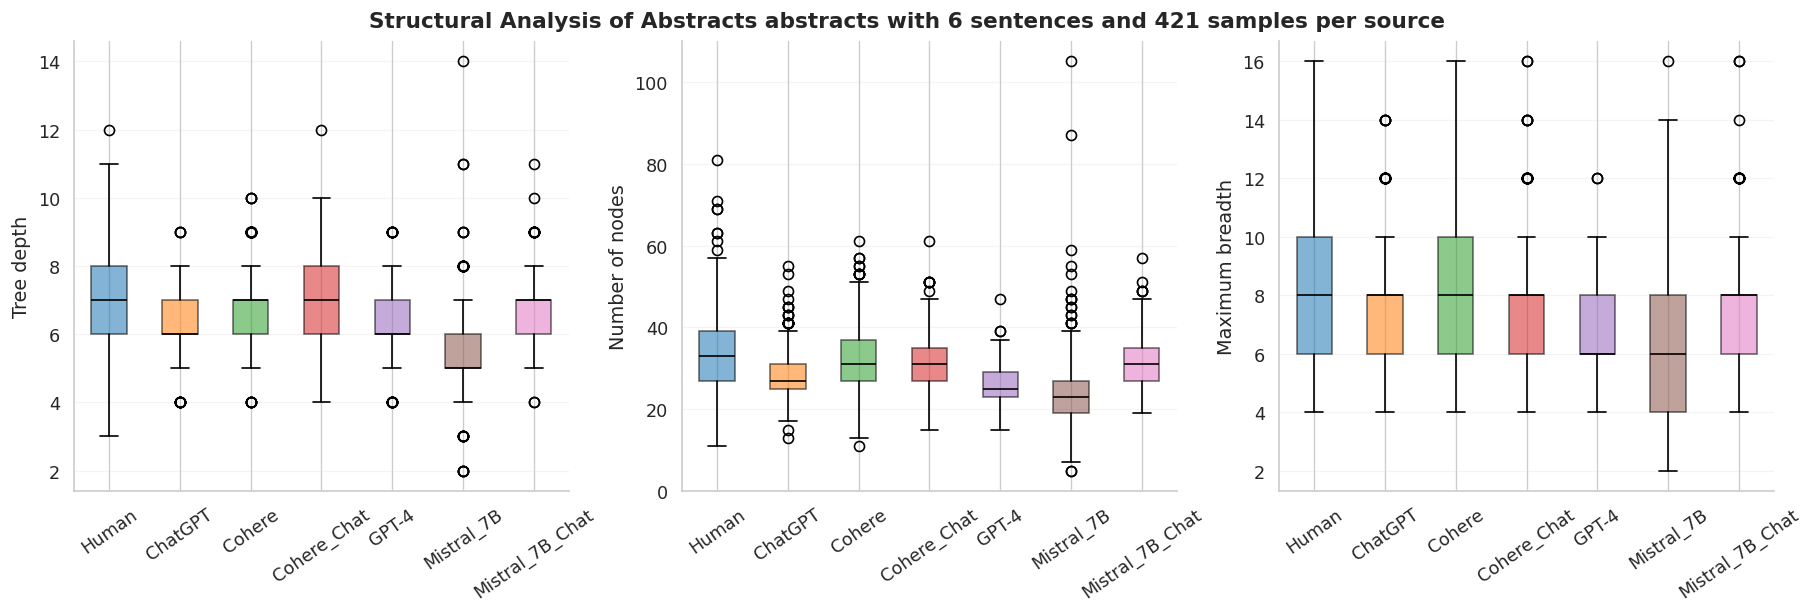

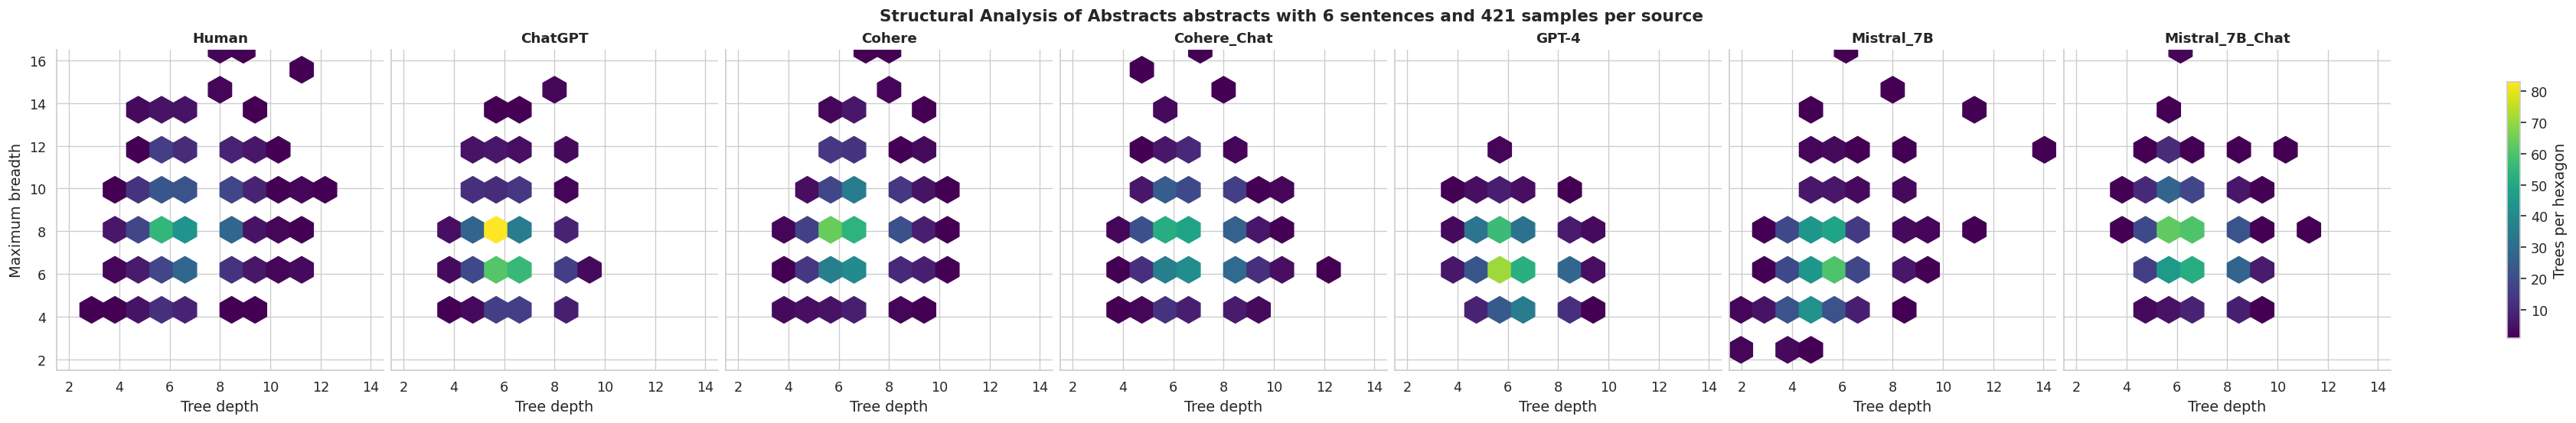

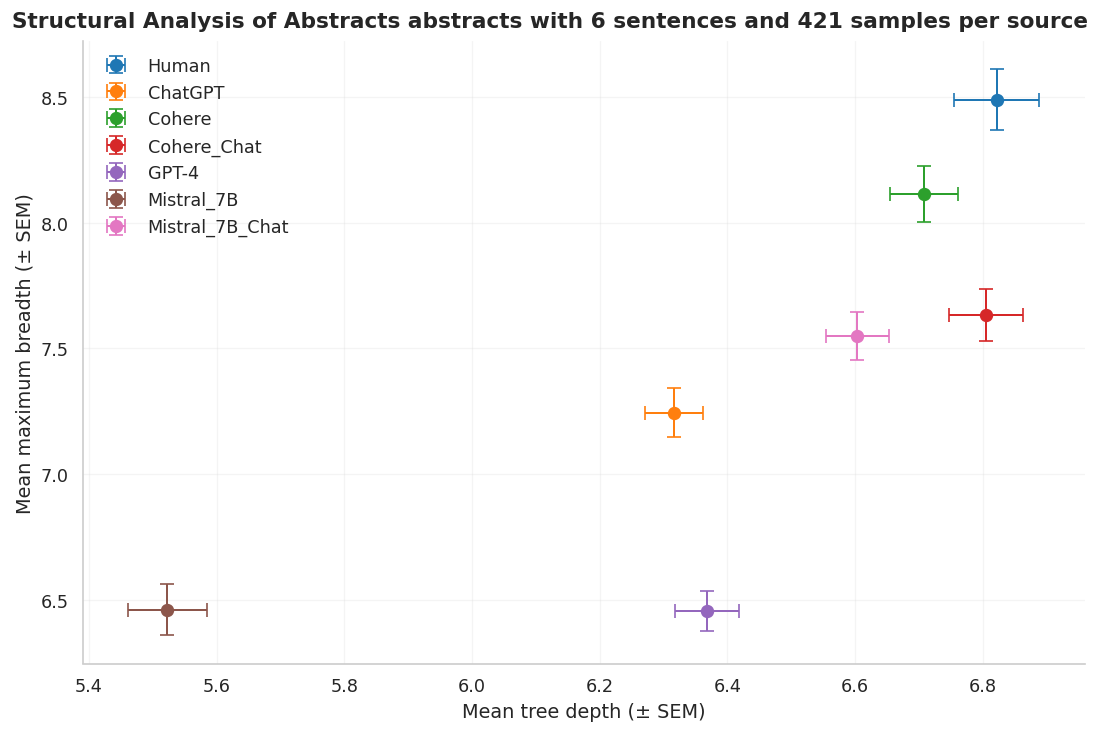

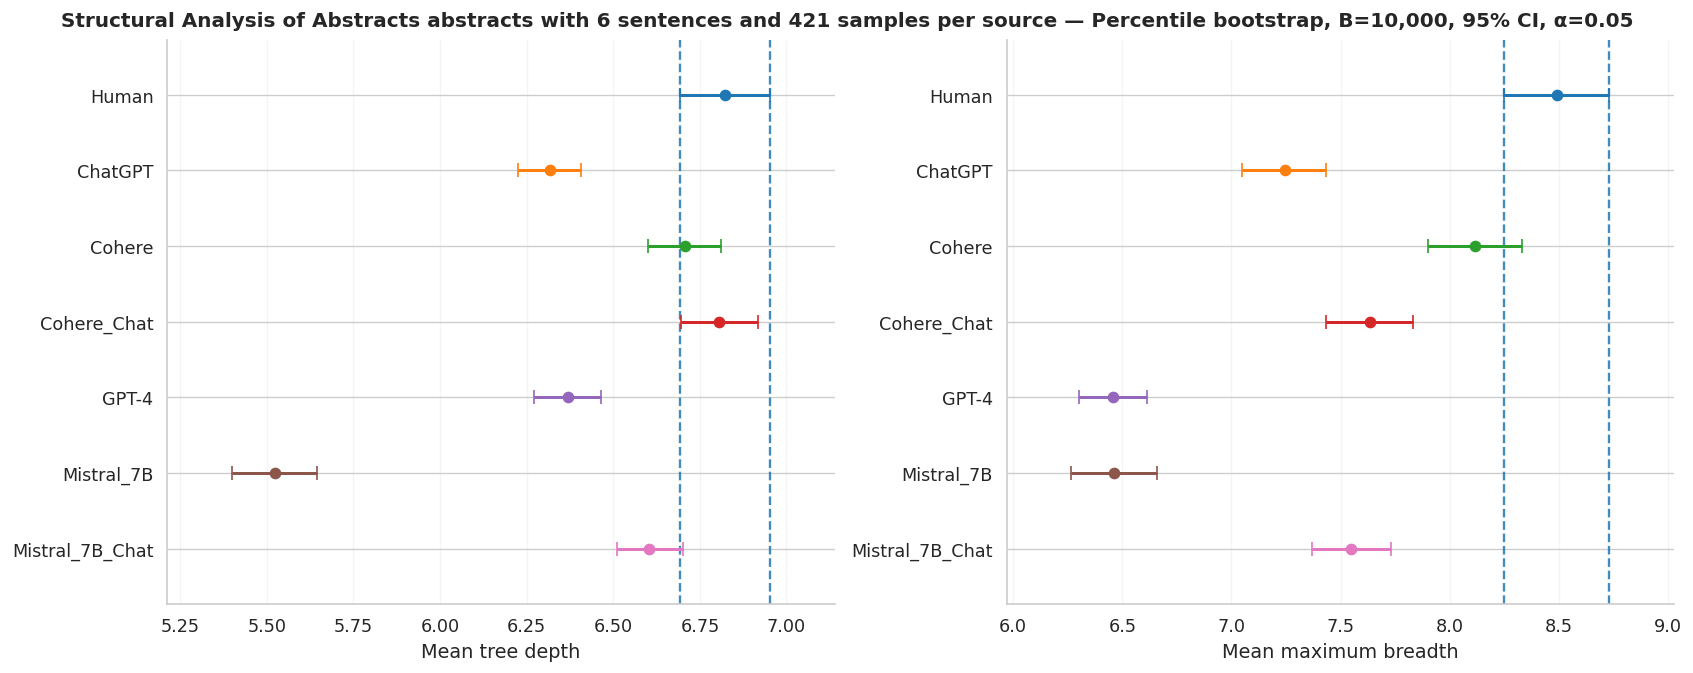

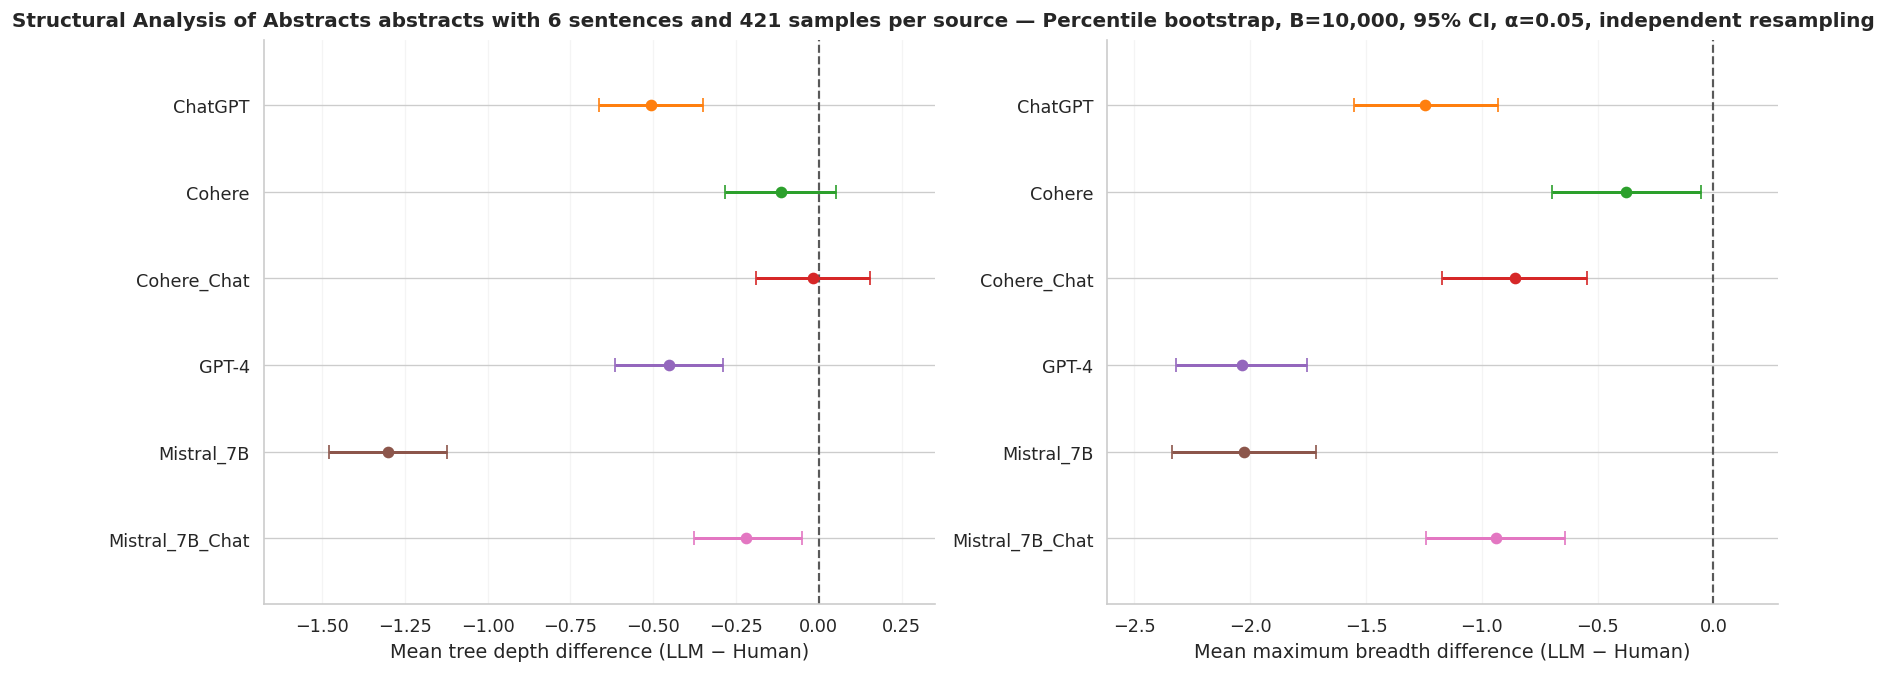

Structural analysis: 2947 trees
Results saved to: /content/rhetorical_signatures/results/sentences_report/structural_analysis/domain-abstracts__prompting-all__attack-null__decoding-greedy__rep-no__range-6-10__best-6__matched-0__proportional__seed-42__bins-10__human-1__first200_per_source

STRUCTURAL SUMMARY — mean ± SD


metric,depth,max_breadth,number_of_nodes
source,,,
ChatGPT,6.32 ± 0.94,7.24 ± 2.00,28.38 ± 6.02
Cohere,6.71 ± 1.09,8.11 ± 2.25,32.83 ± 8.13
Cohere_Chat,6.81 ± 1.18,7.63 ± 2.12,31.22 ± 7.00
GPT-4,6.37 ± 1.02,6.46 ± 1.64,26.17 ± 4.82
Human,6.82 ± 1.37,8.49 ± 2.48,33.80 ± 9.90
Mistral_7B,5.52 ± 1.26,6.46 ± 2.08,23.67 ± 9.34
Mistral_7B_Chat,6.60 ± 1.01,7.55 ± 1.94,30.76 ± 6.16



BOOTSTRAP MEANS — 95% CI


,source,metric,n,mean,ci_low,ci_high,confidence
0,ChatGPT,depth,421,6.316,6.226,6.406,0.95
1,ChatGPT,max_breadth,421,7.245,7.050,7.435,0.95
2,Cohere,depth,421,6.708,6.601,6.810,0.95
3,Cohere,max_breadth,421,8.114,7.900,8.333,0.95
4,Cohere_Chat,depth,421,6.805,6.696,6.917,0.95
5,Cohere_Chat,max_breadth,421,7.634,7.435,7.834,0.95
6,GPT-4,depth,421,6.368,6.271,6.466,0.95
7,GPT-4,max_breadth,421,6.456,6.299,6.613,0.95
8,Human,depth,421,6.822,6.691,6.952,0.95
9,Human,max_breadth,421,8.489,8.247,8.732,0.95



BOOTSTRAP DELTAS — LLM minus Human


,source,reference,metric,n_source,n_reference,delta,ci_low,ci_high,excludes_zero,confidence,bootstrap_method
0,ChatGPT,Human,depth,421,421,-0.506,-0.663,-0.349,True,0.95,independent
1,ChatGPT,Human,max_breadth,421,421,-1.245,-1.553,-0.931,True,0.95,independent
2,Cohere,Human,depth,421,421,-0.114,-0.283,0.052,False,0.95,independent
3,Cohere,Human,max_breadth,421,421,-0.375,-0.698,-0.052,True,0.95,independent
4,Cohere_Chat,Human,depth,421,421,-0.017,-0.190,0.154,False,0.95,independent
5,Cohere_Chat,Human,max_breadth,421,421,-0.855,-1.173,-0.546,True,0.95,independent
6,GPT-4,Human,depth,421,421,-0.454,-0.615,-0.290,True,0.95,independent
7,GPT-4,Human,max_breadth,421,421,-2.033,-2.318,-1.753,True,0.95,independent
8,Mistral_7B,Human,depth,421,421,-1.299,-1.480,-1.121,True,0.95,independent
9,Mistral_7B,Human,max_breadth,421,421,-2.029,-2.337,-1.715,True,0.95,independent



Results saved to: /content/rhetorical_signatures/results/sentences_report/structural_analysis/domain-abstracts__prompting-all__attack-null__decoding-greedy__rep-no__range-6-10__best-6__matched-0__proportional__seed-42__bins-10__human-1__first200_per_source


In [ ]:

# ============================================================
# 07 — RST structural analysis
# ============================================================

# Unique dataset identifier:
# experiment filters + sentence selection + tree subset
structural_dataset_name = (
    f"{run_name}__{Path(output).name}"
    f"__{STRUCTURAL_TREE_SET}"
)

structural_dir, structural_results = (
    structural_inspector.inspect_rst_trees(
        forests_dir=forests_dir,
        results_dir=RESULTS_DIR,
        genre=COMPRESSION_GENRE,
        n_sentences=COMPRESSION_N_SENTENCES,
        sources=STRUCTURAL_SOURCES,
        dataset_name=structural_dataset_name,
        n_boot=STRUCTURAL_N_BOOT,
        confidence=STRUCTURAL_CONFIDENCE,
        seed=STRUCTURAL_SEED,
        human_source=STRUCTURAL_HUMAN_SOURCE,
        delta_method=STRUCTURAL_DELTA_METHOD,
        hex_gridsize=STRUCTURAL_HEX_GRIDSIZE,
        rebuild=STRUCTURAL_REBUILD,
        show=STRUCTURAL_SHOW,
        prompting=PROMPTING,
        attack=ATTACK,
        decoding=DECODING,
        repetition_penalty=REPETITION_PENALTY,
        matched=RST_MATCHED,
        sampling=SAMPLING,
        tree_set=STRUCTURAL_TREE_SET,

    )
)

# ------------------------------------------------------------
# Compact statistical reports
# ------------------------------------------------------------

print("\nSTRUCTURAL SUMMARY — mean ± SD")

summary = structural_results["summary"].copy()
summary["mean_sd"] = summary.apply(
    lambda r: f"{r['mean']:.2f} ± {r['sd']:.2f}",
    axis=1,
)

display(
    summary.pivot(
        index="source",
        columns="metric",
        values="mean_sd",
    )
)

print("\nBOOTSTRAP MEANS — 95% CI")
display(structural_results["bootstrap_means"].round(3))

print("\nBOOTSTRAP DELTAS — LLM minus Human")
display(structural_results["bootstrap_deltas"].round(3))

print(f"\nResults saved to: {structural_dir}")

Recounting all 137 motifs in ChatGPT: 0001__genre-abstracts__source-ChatGPT__n_sentences-6.xml
Recounting all 137 motifs in Cohere: 0002__genre-abstracts__source-Cohere__n_sentences-6.xml
Recounting all 137 motifs in Cohere_Chat: 0003__genre-abstracts__source-Cohere_Chat__n_sentences-6.xml
Recounting all 137 motifs in GPT-4: 0004__genre-abstracts__source-GPT-4__n_sentences-6.xml
Recounting all 137 motifs in Human: 0005__genre-abstracts__source-Human__n_sentences-6.xml
Recounting all 137 motifs in Mistral_7B: 0006__genre-abstracts__source-Mistral_7B__n_sentences-6.xml
Recounting all 137 motifs in Mistral_7B_Chat: 0007__genre-abstracts__source-Mistral_7B_Chat__n_sentences-6.xml


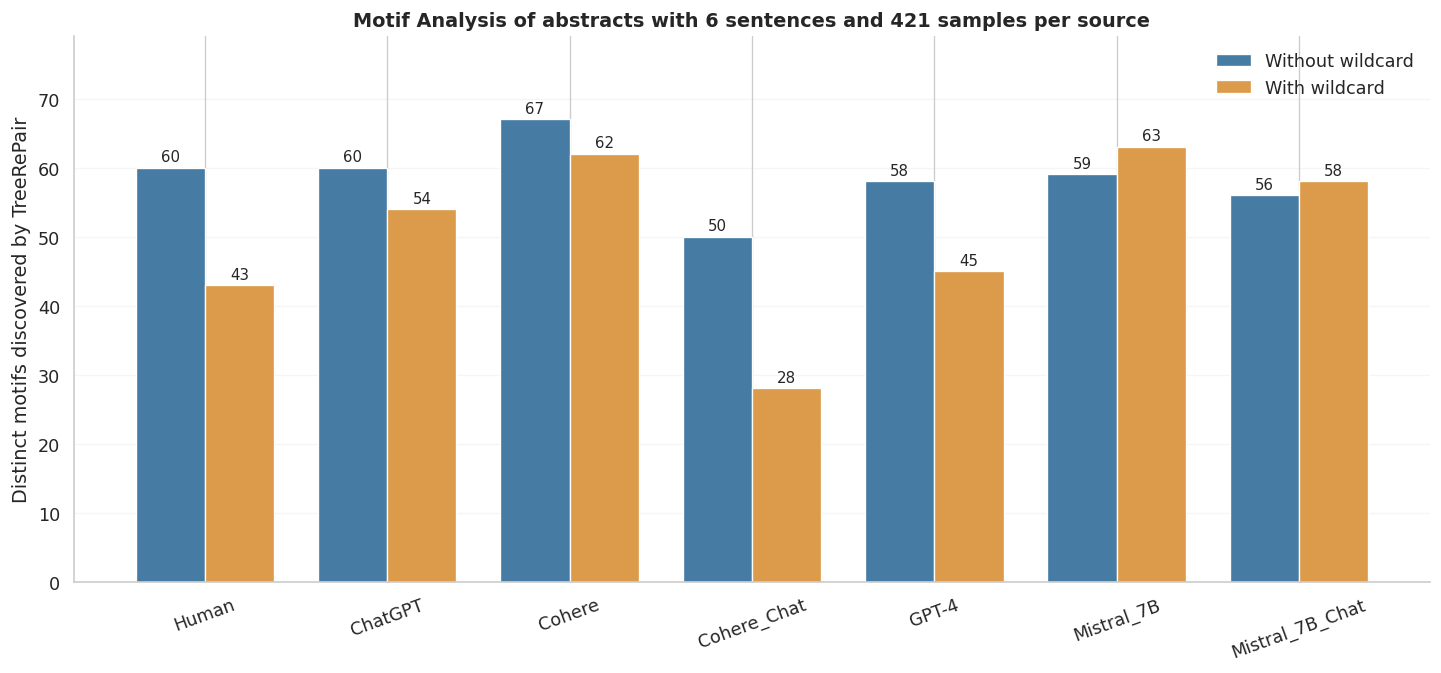

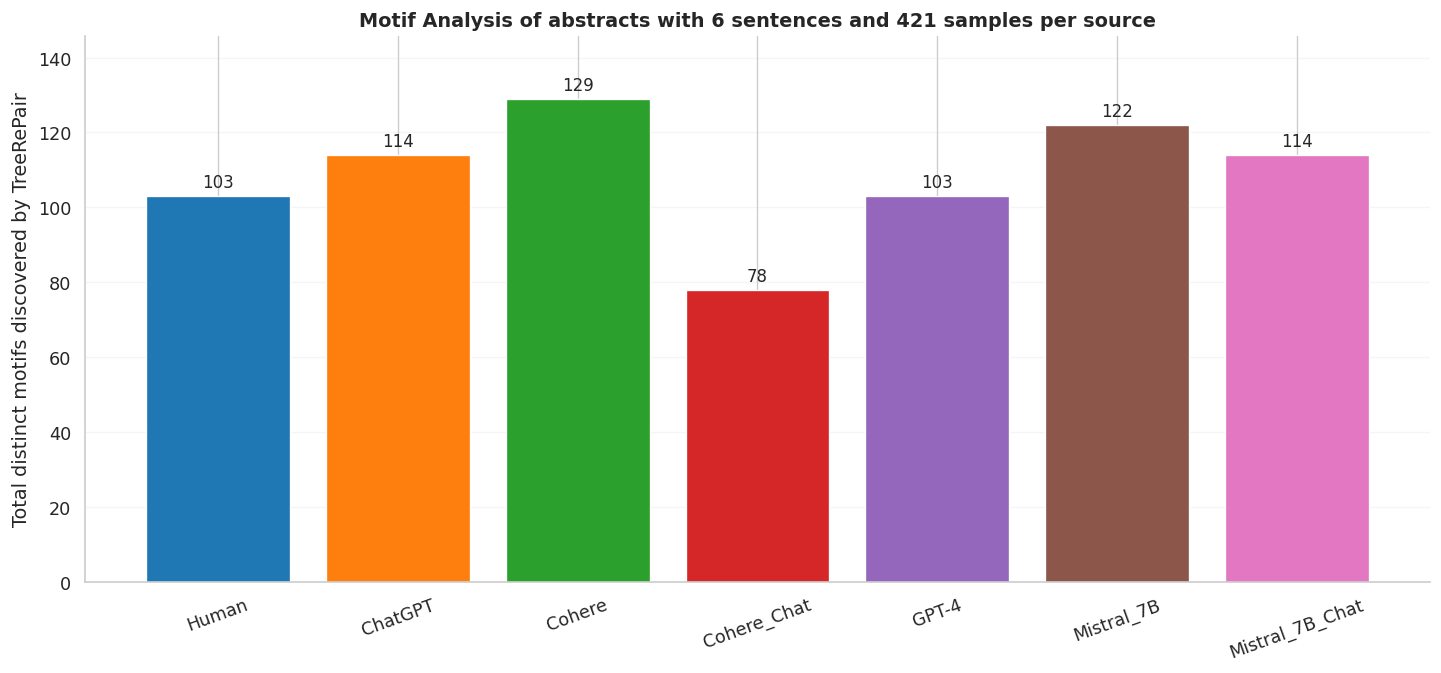

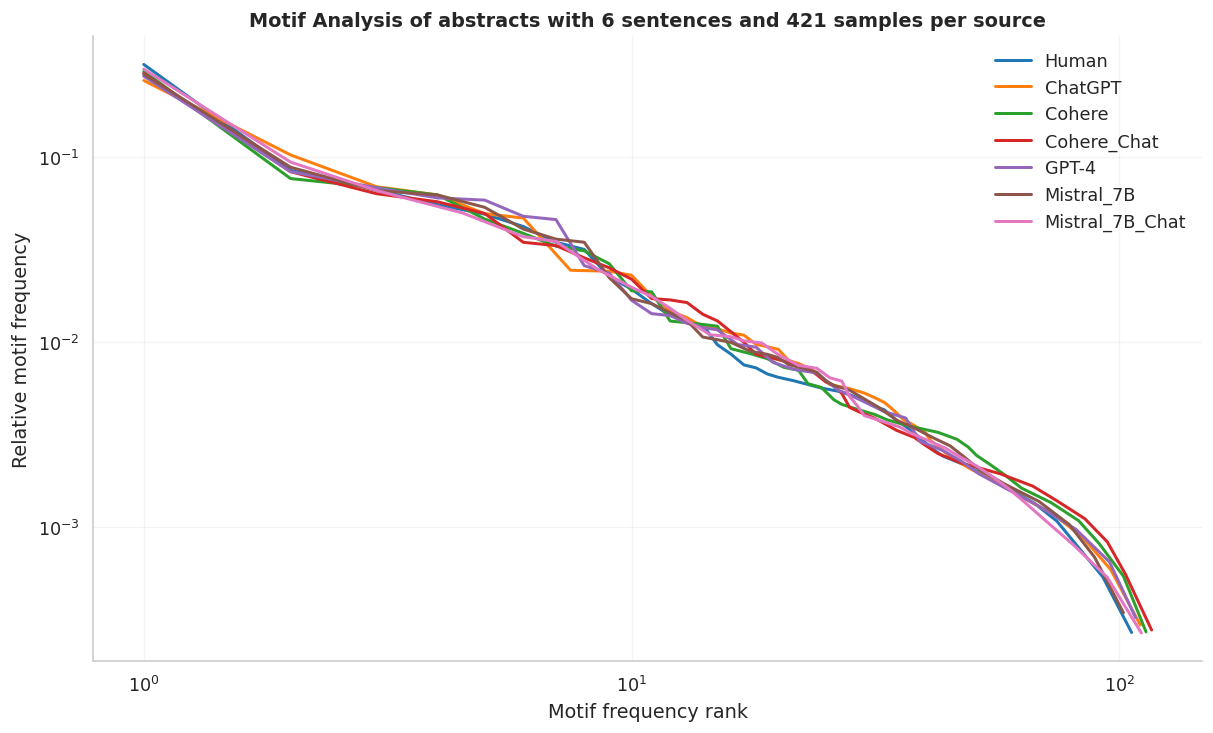

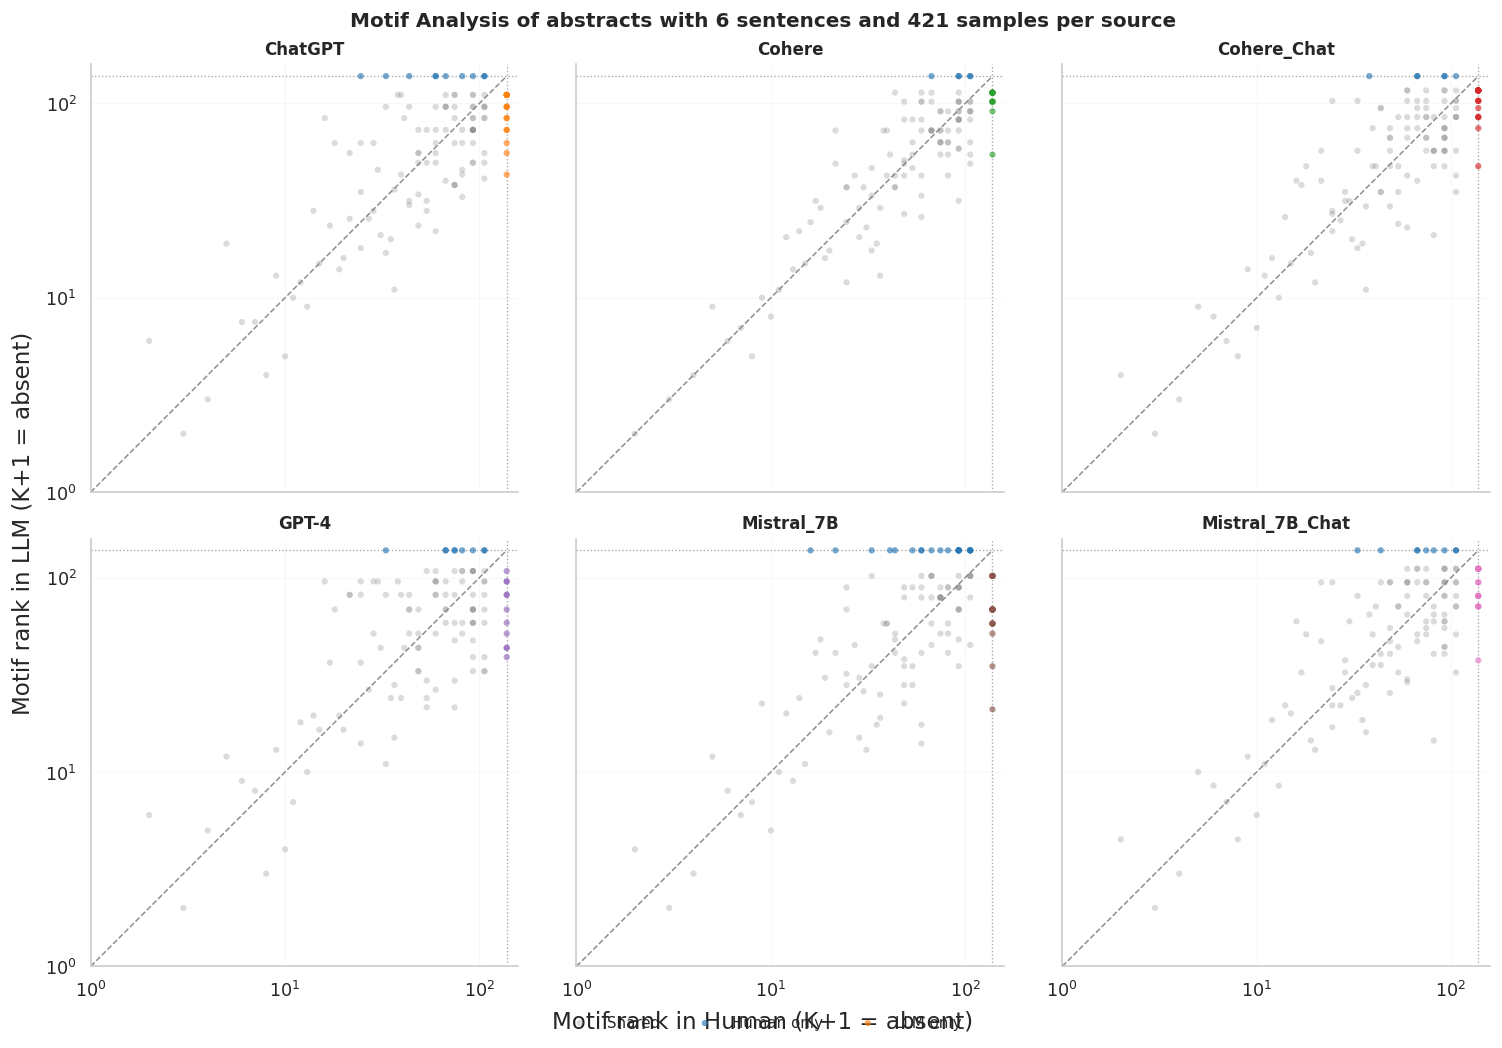

Saved 137 unique motifs and 2947 documents to /content/rhetorical_signatures/results/sentences_report/divergence_analysis/domain-abstracts__prompting-all__attack-null__decoding-greedy__rep-no__range-6-10__best-6__matched-0__proportional__seed-42__bins-10__human-1__first200_per_source
JSD comparisons sorted descending; wildcard motifs excluded from JSD and ranks.
motif_document_frequencies.csv explicitly includes zero counts.
Jensen–Shannon divergence: Human vs LLM


,llm_source,js_divergence_bits,ci_low,ci_high,confidence,n_boot,n_valid,n_documents_a,n_documents_b
0,GPT-4,0.0899,0.0891,0.1150,0.95,10000,10000,421,421
1,ChatGPT,0.0831,0.0822,0.1076,0.95,10000,10000,421,421
2,Mistral_7B,0.0830,0.0824,0.1087,0.95,10000,10000,421,421
3,Mistral_7B_Chat,0.0611,0.0617,0.0831,0.95,10000,10000,421,421
4,Cohere_Chat,0.0521,0.0534,0.0739,0.95,10000,10000,421,421
5,Cohere,0.0307,0.0347,0.0499,0.95,10000,10000,421,421


Jensen–Shannon divergence: LLM vs LLM


,source_a,source_b,js_divergence_bits,ci_low,ci_high,confidence,n_boot,n_valid,n_documents_a,n_documents_b
0,GPT-4,Mistral_7B,0.0904,0.0915,0.1154,0.95,10000,10000,421,421
1,Cohere,Mistral_7B,0.0627,0.0657,0.0869,0.95,10000,10000,421,421
2,ChatGPT,Mistral_7B,0.0623,0.0652,0.0869,0.95,10000,10000,421,421
3,Cohere,GPT-4,0.0554,0.0581,0.0792,0.95,10000,10000,421,421
4,Cohere_Chat,Mistral_7B,0.0543,0.0584,0.0781,0.95,10000,10000,421,421
5,GPT-4,Mistral_7B_Chat,0.0515,0.0549,0.0731,0.95,10000,10000,421,421
6,Mistral_7B,Mistral_7B_Chat,0.0515,0.0550,0.0745,0.95,10000,10000,421,421
7,Cohere_Chat,GPT-4,0.0473,0.0513,0.0697,0.95,10000,10000,421,421
8,ChatGPT,Cohere,0.0448,0.0478,0.0666,0.95,10000,10000,421,421
9,Cohere,Mistral_7B_Chat,0.0366,0.0403,0.0568,0.95,10000,10000,421,421


Results saved to: /content/rhetorical_signatures/results/sentences_report/divergence_analysis/domain-abstracts__prompting-all__attack-null__decoding-greedy__rep-no__range-6-10__best-6__matched-0__proportional__seed-42__bins-10__human-1__first200_per_source


In [ ]:

# ============================================================
# CELL 08 — Motif divergence analysis
# ============================================================

divergence_dir, divergence_results = (
    divergence_analyzer.analyze_motif_divergence(
        motifs_dir=motifs_dir,
        forests_dir=forests_dir,
        results_dir=RESULTS_DIR,
        genre=COMPRESSION_GENRE,
        n_sentences=COMPRESSION_N_SENTENCES,
        sources=COMPRESSION_SOURCES,
        dataset_name=structural_dataset_name,
        prompting=PROMPTING,
        attack=ATTACK,
        decoding=DECODING,
        repetition_penalty=REPETITION_PENALTY,
        matched=RST_MATCHED,
        sampling=SAMPLING,
        tree_set=STRUCTURAL_TREE_SET,
        human_source="Human",
        n_boot=10000,
        confidence=0.95,
        seed=42,
        top_k=100,
        rebuild=False,
        show=True,
    )
)


divergence_analyzer.display_js_tables(
    divergence_results,
    decimals=4
)

print(f"Results saved to: {divergence_dir}")

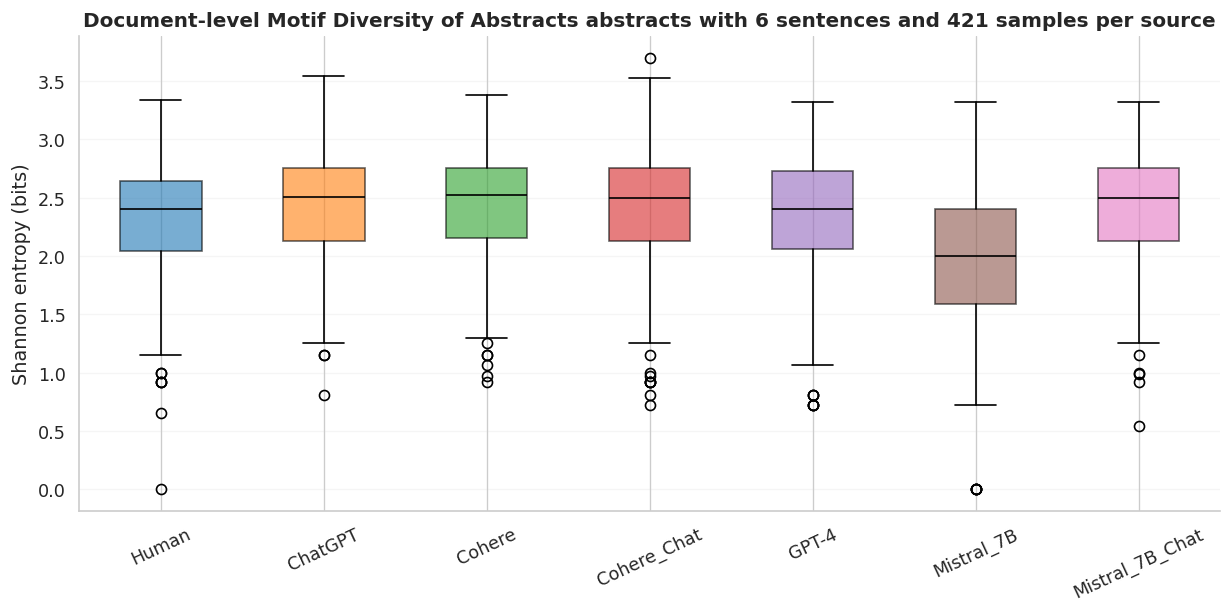

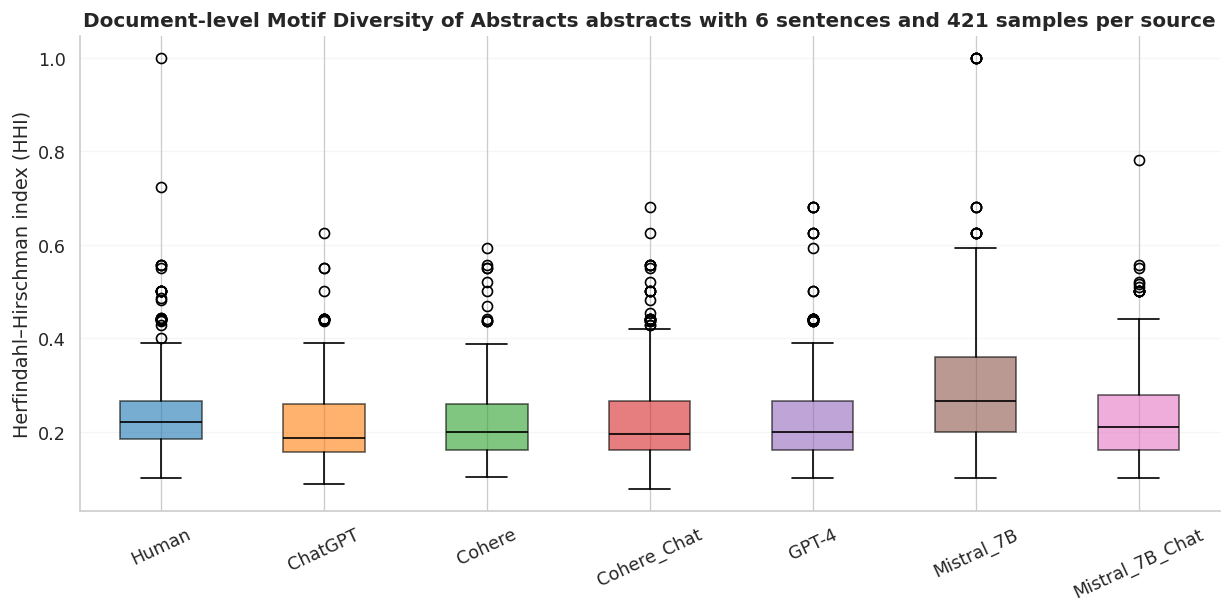

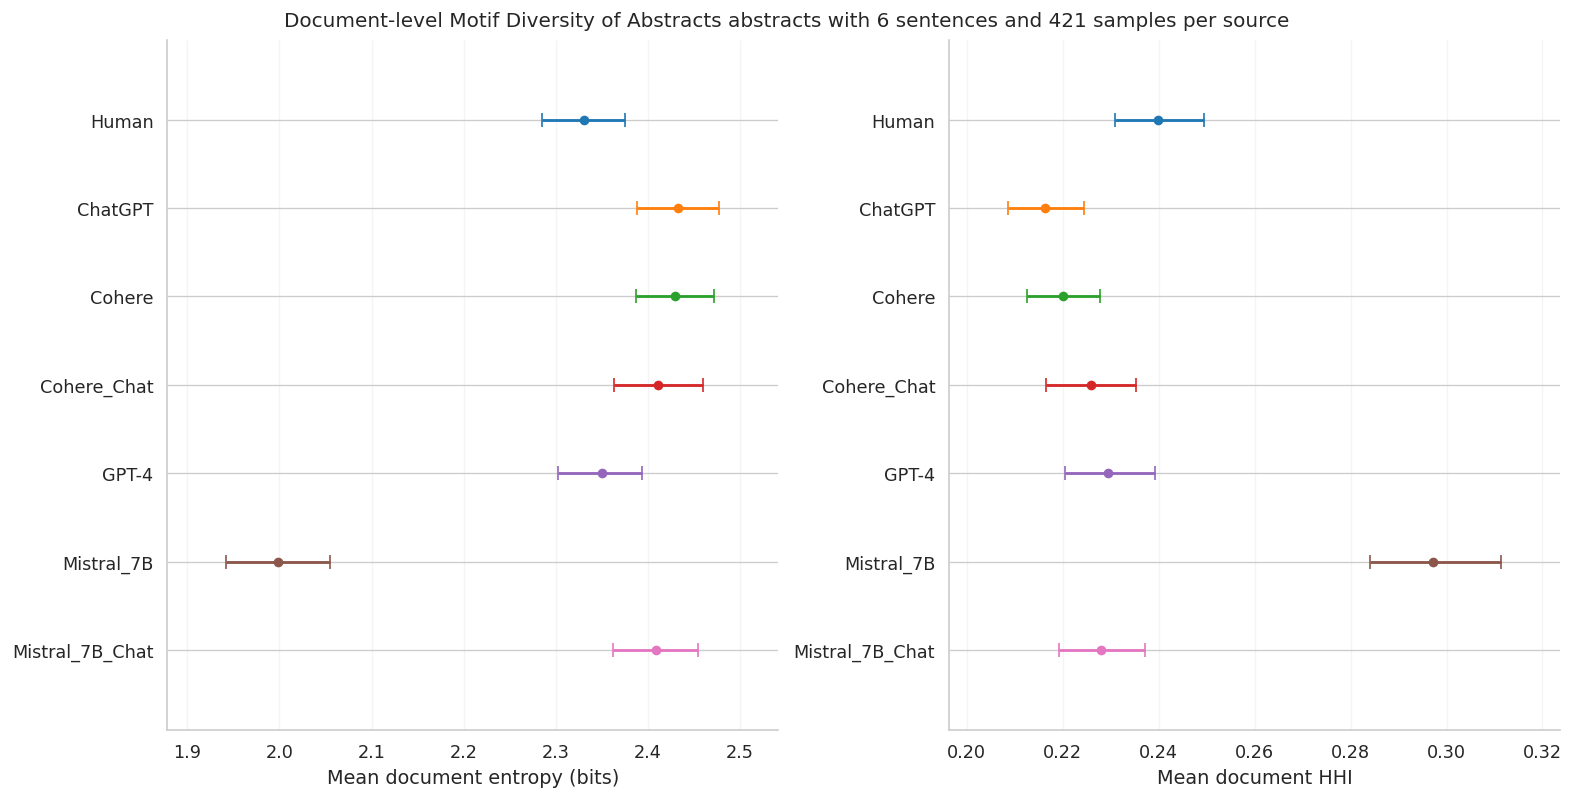

Document-level diversity saved to: /content/rhetorical_signatures/results/sentences_report/divergence_analysis/domain-abstracts__prompting-all__attack-null__decoding-greedy__rep-no__range-6-10__best-6__matched-0__proportional__seed-42__bins-10__human-1__first200_per_source
Document-level entropy and HHI


,source,metric,n_documents_total,n_documents_valid,n_documents_empty,mean,sd,sem,median,ci_low,ci_high,n_boot,confidence
0,Human,entropy_bits,421,421,0,2.3302,0.4743,0.0231,2.4040,2.2853,2.3753,10000,0.95
1,ChatGPT,entropy_bits,421,421,0,2.4328,0.4681,0.0228,2.5033,2.3876,2.4772,10000,0.95
2,Cohere,entropy_bits,421,421,0,2.4298,0.4449,0.0217,2.5216,2.3870,2.4720,10000,0.95
3,Cohere_Chat,entropy_bits,421,421,0,2.4115,0.5039,0.0246,2.5000,2.3632,2.4595,10000,0.95
4,GPT-4,entropy_bits,421,421,0,2.3496,0.4844,0.0236,2.4056,2.3029,2.3939,10000,0.95
5,Mistral_7B,entropy_bits,421,421,0,1.9984,0.5943,0.0290,2.0000,1.9424,2.0551,10000,0.95
6,Mistral_7B_Chat,entropy_bits,421,421,0,2.4084,0.4851,0.0236,2.5000,2.3620,2.4541,10000,0.95
7,Human,hhi,421,421,0,0.2398,0.0967,0.0047,0.2200,0.2308,0.2494,10000,0.95
8,ChatGPT,hhi,421,421,0,0.2164,0.0838,0.0041,0.1875,0.2086,0.2245,10000,0.95
9,Cohere,hhi,421,421,0,0.2200,0.0794,0.0039,0.2000,0.2126,0.2277,10000,0.95


LLM − Human differences


,source,reference,metric,delta,ci_low,ci_high,excludes_zero,n_boot,confidence
0,ChatGPT,Human,entropy_bits,0.1026,0.0389,0.1655,True,10000,0.95
1,Cohere,Human,entropy_bits,0.0996,0.0367,0.1605,True,10000,0.95
2,Cohere_Chat,Human,entropy_bits,0.0813,0.0163,0.1482,True,10000,0.95
3,GPT-4,Human,entropy_bits,0.0194,-0.0459,0.0818,False,10000,0.95
4,Mistral_7B,Human,entropy_bits,-0.3318,-0.4038,-0.2588,True,10000,0.95
5,Mistral_7B_Chat,Human,entropy_bits,0.0782,0.0131,0.1429,True,10000,0.95
6,ChatGPT,Human,hhi,-0.0234,-0.0356,-0.0113,True,10000,0.95
7,Cohere,Human,hhi,-0.0198,-0.0318,-0.0082,True,10000,0.95
8,Cohere_Chat,Human,hhi,-0.0140,-0.0274,-0.0009,True,10000,0.95
9,GPT-4,Human,hhi,-0.0103,-0.0238,0.0028,False,10000,0.95


In [ ]:

# ============================================================
# CELL 09 — Document-level motif diversity
# ============================================================

diversity_dir, diversity_results = (
    diversity_analyzer.analyze_motif_diversity(
        divergence_dir=divergence_dir,
        genre=COMPRESSION_GENRE,
        n_sentences=COMPRESSION_N_SENTENCES,
        human_source="Human",
        n_boot=10000,
        confidence=0.95,
        seed=42,
        rebuild=False,
        show=True,
    )
)

print("Document-level entropy and HHI")
display(
    diversity_results["motif_diversity_summary"].round(4)
)

print("LLM − Human differences")
display(
    diversity_results["motif_diversity_deltas"].round(4)
)

# MATCHED

Loaded existing matched dataset: /content/rhetorical_signatures/data/filtered/matched/genre-reddit/prompting-all/attack-null/decoding-greedy/repetition_penalty-no/k-6/all


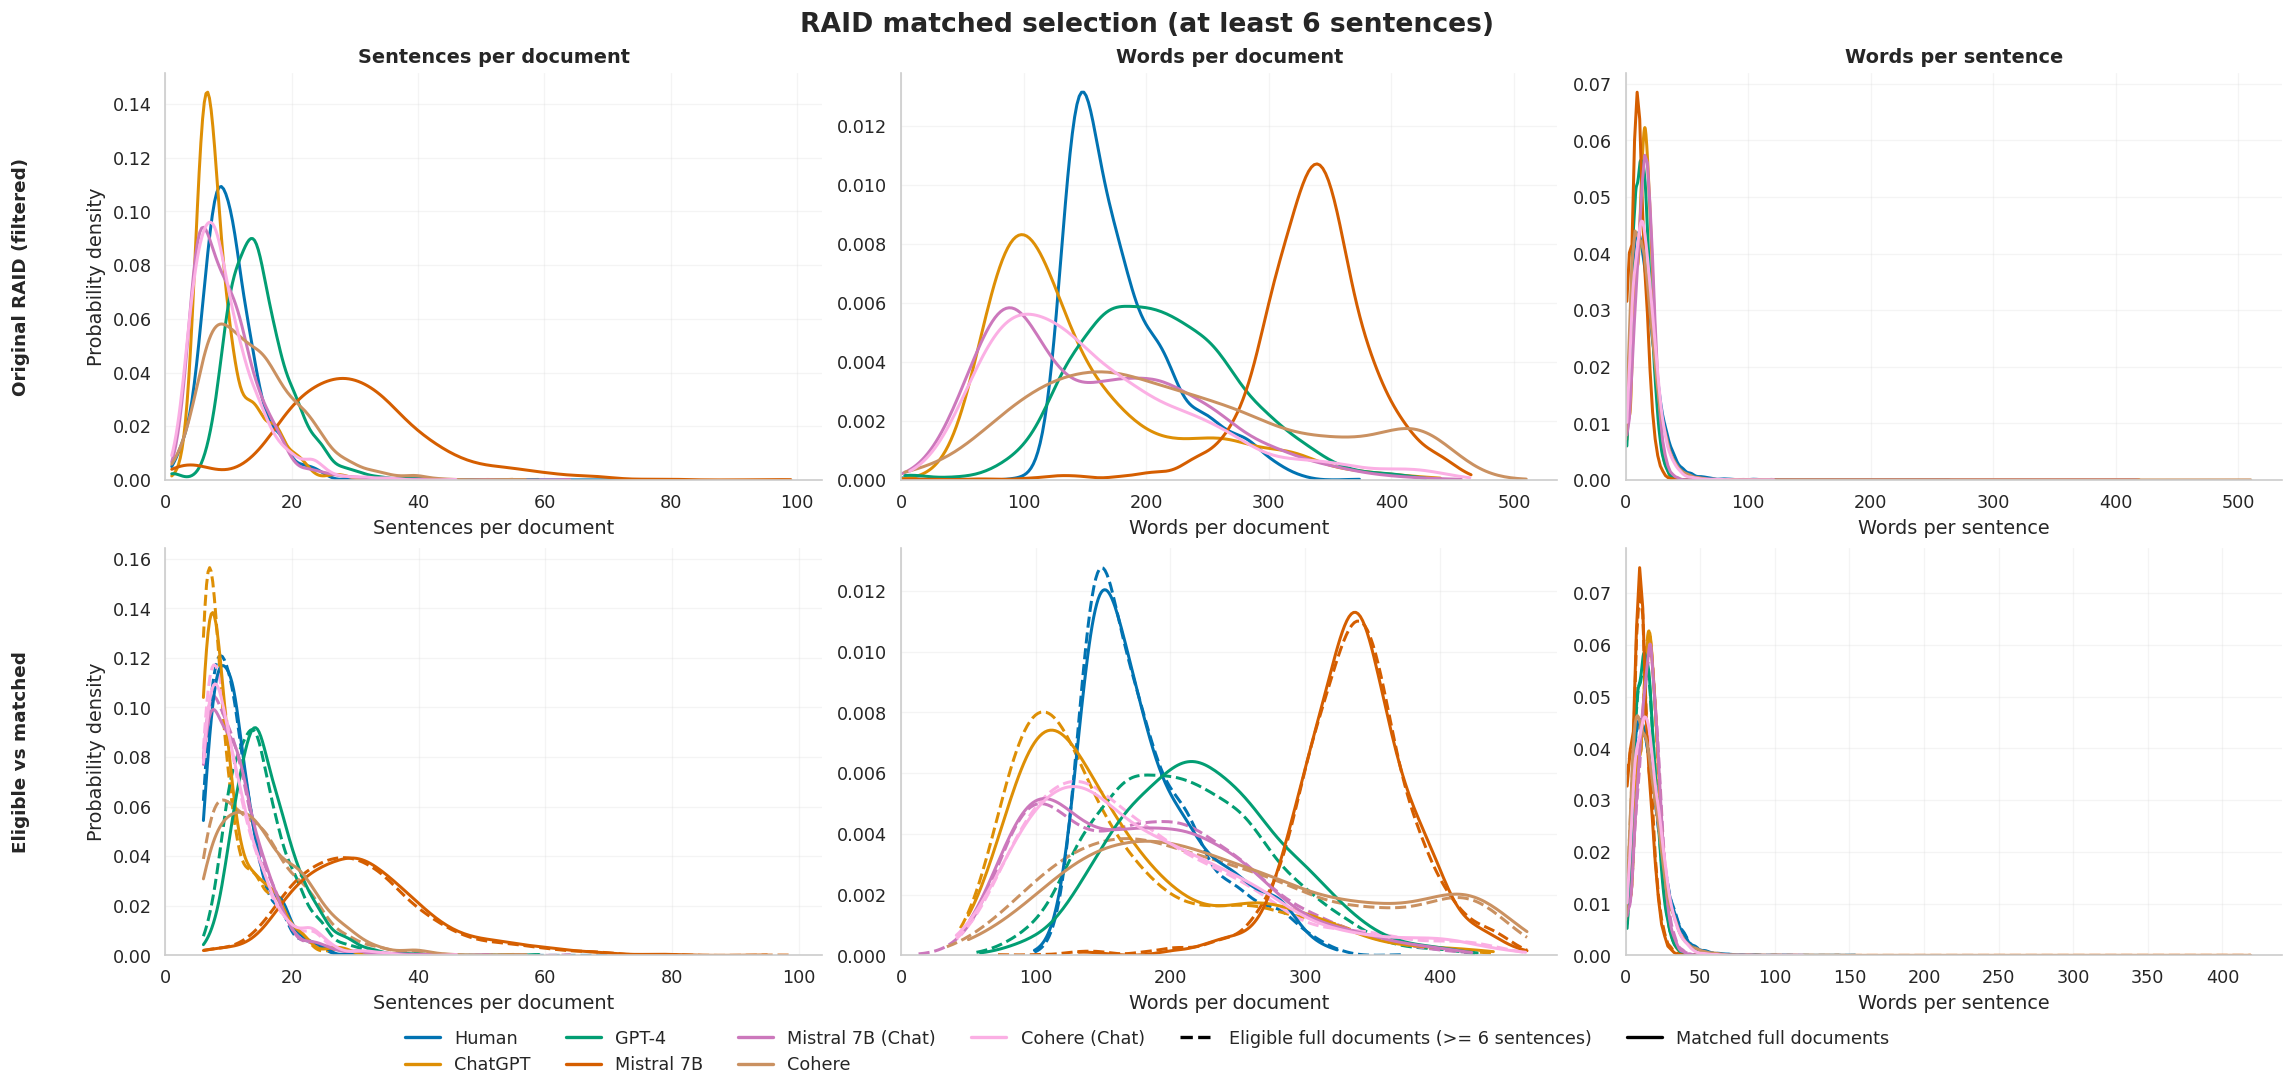

,source,n_documents,n_sentences_total,sentences_per_document_mean,sentences_per_document_std,sentences_per_document_median,sentences_per_document_q05,sentences_per_document_q25,sentences_per_document_q75,sentences_per_document_q95,...,words_per_document_q25,words_per_document_q75,words_per_document_q95,words_per_sentence_mean,words_per_sentence_std,words_per_sentence_median,words_per_sentence_q05,words_per_sentence_q25,words_per_sentence_q75,words_per_sentence_q95
0,ChatGPT,818,8511,10.404645,4.831945,9.0,6.0,7.0,12.00,20.0,...,103.25,196.50,318.15,15.433322,6.488948,15.0,5.0,11.0,20.0,26.0
1,Cohere,818,12986,15.875306,7.401022,15.0,7.0,10.0,20.00,29.0,...,160.25,325.75,429.00,15.482212,10.565892,14.0,3.0,8.0,21.0,34.0
2,Cohere (Chat),818,9280,11.344743,5.299914,10.0,6.0,8.0,13.75,23.0,...,119.00,230.50,351.30,15.909914,9.366038,15.0,4.0,9.0,21.0,33.0
3,GPT-4,818,13285,16.240831,5.260596,15.0,10.0,13.0,19.00,26.0,...,181.25,265.75,330.15,13.862928,6.591899,13.0,4.0,9.0,18.0,25.0
4,Human,818,9175,11.216381,4.035749,10.0,6.0,8.0,13.00,19.0,...,149.00,208.00,274.30,16.292207,10.670806,14.0,4.0,9.0,21.0,36.0
5,Mistral 7B,818,26012,31.799511,11.577059,30.0,17.0,24.0,37.75,54.0,...,314.00,362.00,404.15,10.625019,9.315091,10.0,2.0,6.0,14.0,21.0
6,Mistral 7B (Chat),818,9220,11.271394,5.082159,10.0,6.0,8.0,13.00,20.0,...,113.00,232.00,319.00,15.805748,6.810094,16.0,5.0,11.0,20.0,27.0


In [6]:
matched, matched_statistics, matched_metadata = (
    matched_selector.select_matched_dataset(
        documents,
        sentences,
        k=K_SENTENCES,
        m=M_DOCUMENTS,
        domain=DOMAIN,
        prompting=PROMPTING,
        attack=ATTACK,
        decoding=DECODING,
        repetition_penalty=REPETITION_PENALTY,
        seed=SEED,
        save=True,
        plot=True,
    )
)

display(matched_statistics)